# CHIRPS v2 Final daily rainfall EDA

Rainfall summaries use the shared study configuration and validated, cumulative source inventory. Expanded development covers training 2020–2024; held-out test 2025 is excluded from ordinary analysis. This extends the paper-inspired reconstruction and does not claim exact replication or forecast readiness.

Native CHIRPS v2 Final precipitation remains **0.05°, mm/day, source-day UTC**, without resampling or peat masking. See [CHIRPS documentation](https://www.chc.ucsb.edu/data/chirps), [Earth Engine catalog](https://developers.google.com/earth-engine/datasets/catalog/UCSB-CHG_CHIRPS_DAILY), and `docs/chirps-refresh.md` for bounded refresh commands. Actual dates depend on publication and validated local files.

Install the repository editable in this environment first. Run from the root or EDA directory; source data remain in one location. All figures below describe province-center pixels, **not peatland model coverage**.


In [1]:
import os
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely
from shapely.geometry import shape
from shapely.plotting import plot_polygon
from peatguard import find_root, load_study
from peatguard.chirps import CHIRPSArchive, load_development, rainfall_summary

ROOT = find_root()
PROFILE = "expanded"
AS_OF = os.getenv("PEATGUARD_AS_OF")  # Fixed UTC snapshot when provided.
INCLUDE_HELD_OUT = False  # Deliberate final evaluation only; record opening before analysis.
study = load_study(root=ROOT, profile=PROFILE, as_of=AS_OF)
loaded = load_development(study, include_held_out=INCLUDE_HELD_OUT)
annual = loaded["annual"]
latitude, longitude = loaded["latitude"], loaded["longitude"]
print("Profile:", study.profile, "Cutoff:", study.as_of.isoformat())
print("Held-out analysis explicitly opened:", loaded["held_out_opened"])
print("Actual loaded days:", {year: len(item["dates"]) for year, item in annual.items()})
print("Grid:", len(latitude), "rows ×", len(longitude), "columns; mm/day")


Profile: expanded Cutoff: 2026-10-25T11:11:35.847461+00:00
Held-out analysis explicitly opened: False
Actual loaded days: {2020: 366, 2021: 365, 2022: 365, 2023: 365, 2024: 366}
Grid: 190 rows × 220 columns; mm/day


## Available source files: training and 2025 test

The table includes test-year file availability. The plots below still use training dates only. File presence and recorded source coverage do not establish complete model-label coverage.

In [2]:
source_manifest = json.loads((ROOT / study.config["sources"]["chirps"]["directory"] / "manifest.json").read_text())
source_availability = pd.DataFrame([
    {"year": item["year"], "role": role,
     "file_present": (ROOT / item["file"]).is_file(),
     "recorded_days": item.get("days", "annual map"), "file": item["file"]}
    for item in source_manifest["years"]
    for role, (start, end) in study.profile_config["splits"].items()
    if int(start[:4]) <= int(item["year"]) <= int(end[:4])
]).sort_values(["year", "role"]).reset_index(drop=True)
print("2025 is registered as TEST data; training summaries below stop at 2024.")
display(source_availability)


2025 is registered as TEST data; training summaries below stop at 2024.


,year,role,file_present,recorded_days,file
0,2020,train,True,366,data/interim/chirps_v2/chirps_v2_kalimantan_20...
1,2021,train,True,365,data/interim/chirps_v2/chirps_v2_kalimantan_20...
2,2022,train,True,365,data/interim/chirps_v2/chirps_v2_kalimantan_20...
3,2023,train,True,365,data/interim/chirps_v2/chirps_v2_kalimantan_20...
4,2024,train,True,366,data/interim/chirps_v2/chirps_v2_kalimantan_20...
5,2025,test,True,365,data/interim/chirps_v2/.partitions/2025-570038...


## Coverage before interpretation

Coverage is based on actual dates and validated file contents. A partial file is not a full year. Missing source days remain visible, and source validation does not establish model eligibility or historical forecast availability. Provider publication discovery is performed by the refresh script, not automatically by this notebook.


In [3]:
dates = pd.DatetimeIndex([day for item in annual.values() for day in item["dates"]])
allowed = pd.DatetimeIndex(pd.to_datetime(study.development_dates() if not INCLUDE_HELD_OUT
                                        else [str(day) for day in pd.date_range(study.start, study.end).date]))
print(f"Loaded: {len(dates):,} / requested analysis days: {len(allowed):,}")
print("Missing analysis days:", len(allowed.difference(dates)))
assert dates.is_unique and dates.is_monotonic_increasing
assert dates.isin(allowed).all()


Loaded: 1,827 / requested analysis days: 1,827
Missing analysis days: 0


## Province mask

This preserves the previous five BIG province polygons and pixel-center selection. It is a descriptive mask; it does not alter the candidate 5 km study lattice or peat polygons.


In [4]:
with (ROOT / study.config["boundaries"]["provinces"]).open(encoding="utf-8") as stream:
    province_geojson = json.load(stream)

def keep_xy(coordinates):
    if isinstance(coordinates[0], (int, float)):
        return coordinates[:2]
    return [keep_xy(part) for part in coordinates]

provinces = [(feature["properties"]["WADMPR"], shape({
    "type": feature["geometry"]["type"],
    "coordinates": keep_xy(feature["geometry"]["coordinates"]),
})) for feature in province_geojson["features"]]
province_union = shapely.union_all([geometry for _, geometry in provinces])
lon_grid, lat_grid = np.meshgrid(longitude, latitude)
province_mask = shapely.contains_xy(province_union, lon_grid, lat_grid)
print("Native pixel centers inside provinces:", int(province_mask.sum()))
summary = rainfall_summary(loaded, province_mask)
quality, daily, monthly = summary["quality"], summary["daily"], summary["monthly"]
quality


Native pixel centers inside provinces: 17382


,days_present,calendar_days,complete_calendar_year,first_day,last_day,province_missing_pct,province_valid_pixel_days
year,,,,,,,
2020,366,366,True,2020-01-01,2020-12-31,0.005753,6361446
2021,365,365,True,2021-01-01,2021-12-31,0.005753,6344065
2022,365,365,True,2022-01-01,2022-12-31,0.005753,6344065
2023,365,365,True,2023-01-01,2023-12-31,0.005753,6344065
2024,366,366,True,2024-01-01,2024-12-31,0.005753,6361446


## Temporal patterns and actual-day denominators

A dry day is zero; a missing day remains missing. Daily means use finite province pixels, and the quality table reports missing pixel-days. Monthly bars are totals over observed valid days, with incomplete months hatched and their denominators shown below. These partial totals must not be compared as complete calendar-month totals.


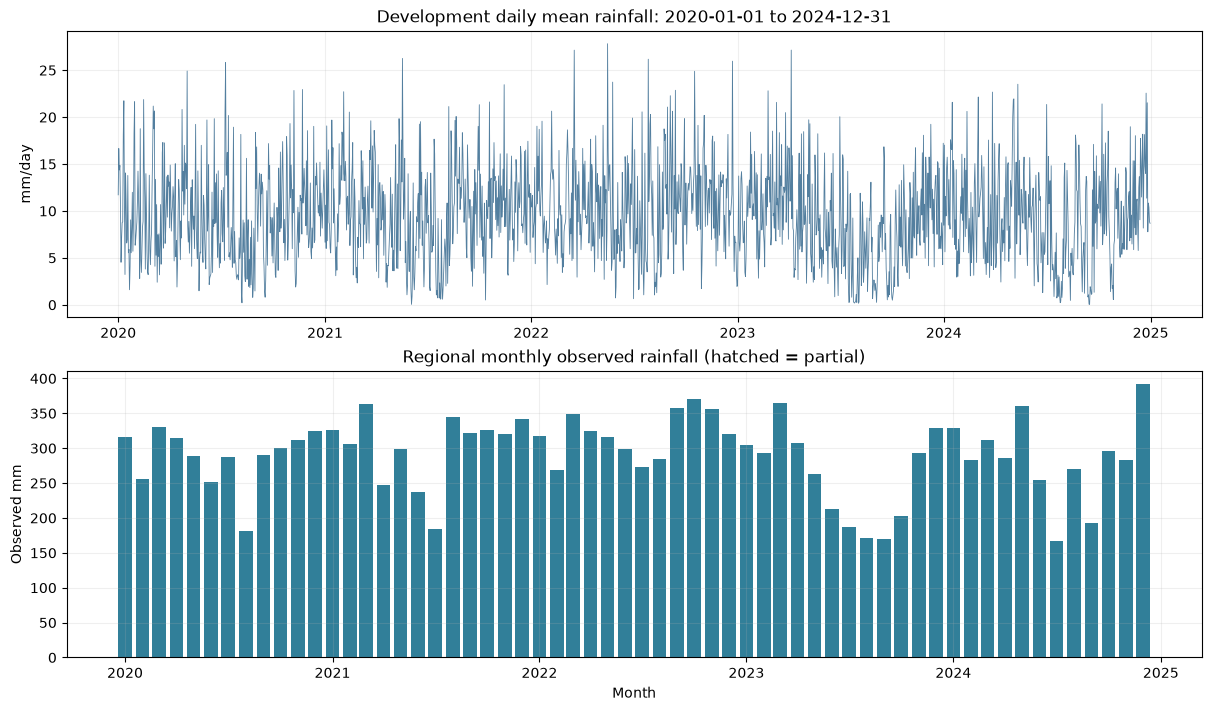

,observed_total_mm,valid_days,calendar_days,period_status
2020-01-01,316.74,31,31,complete
2020-02-01,255.14,29,29,complete
2020-03-01,330.51,31,31,complete
2020-04-01,314.58,30,30,complete
2020-05-01,288.58,31,31,complete
2020-06-01,251.46,30,30,complete
2020-07-01,287.16,31,31,complete
2020-08-01,181.79,31,31,complete
2020-09-01,289.76,30,30,complete
2020-10-01,299.75,31,31,complete


In [5]:
period_label = f"{dates.min():%Y-%m-%d} to {dates.max():%Y-%m-%d}"
fig, axes = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)
axes[0].plot(daily.index, daily.mean_mm_day, color="#537f9f", linewidth=.6)
axes[0].set(title=f"Development daily mean rainfall: {period_label}", ylabel="mm/day")
bars = axes[1].bar(monthly.index, monthly.observed_total_mm, width=24, color="#317f99")
for bar, complete in zip(bars, monthly.complete_month):
    if not complete:
        bar.set_hatch("///")
        bar.set_edgecolor("#b25020")
axes[1].set(title="Regional monthly observed rainfall (hatched = partial)",
            ylabel="Observed mm", xlabel="Month")
for ax in axes:
    ax.grid(alpha=.2)
plt.show()
monthly[["observed_total_mm", "valid_days", "calendar_days", "period_status"]].round(2)


In [6]:
# Only complete calendar months contribute to this seasonal comparison.
summary["climatology_complete_months"].rename(columns={"count": "complete_months"}).round(2)


,mean,min,max,complete_months
1,318.62,304.83,328.62,5
2,281.32,255.14,305.92,5
3,343.92,311.06,364.86,5
4,295.78,246.56,324.96,5
5,305.21,262.46,360.54,5
6,251.15,213.39,298.37,5
7,219.81,167.18,287.16,5
8,250.61,171.55,344.74,5
9,266.11,169.64,357.26,5
10,298.74,202.41,370.07,5


## Spatial rainfall pattern from complete years only

The mean annual-total map excludes incomplete calendar years. Within a complete year, a missing pixel-day makes that pixel's annual total missing rather than reducing its total or converting it to zero. The title lists the actual included years. No map is produced if no complete year is available.


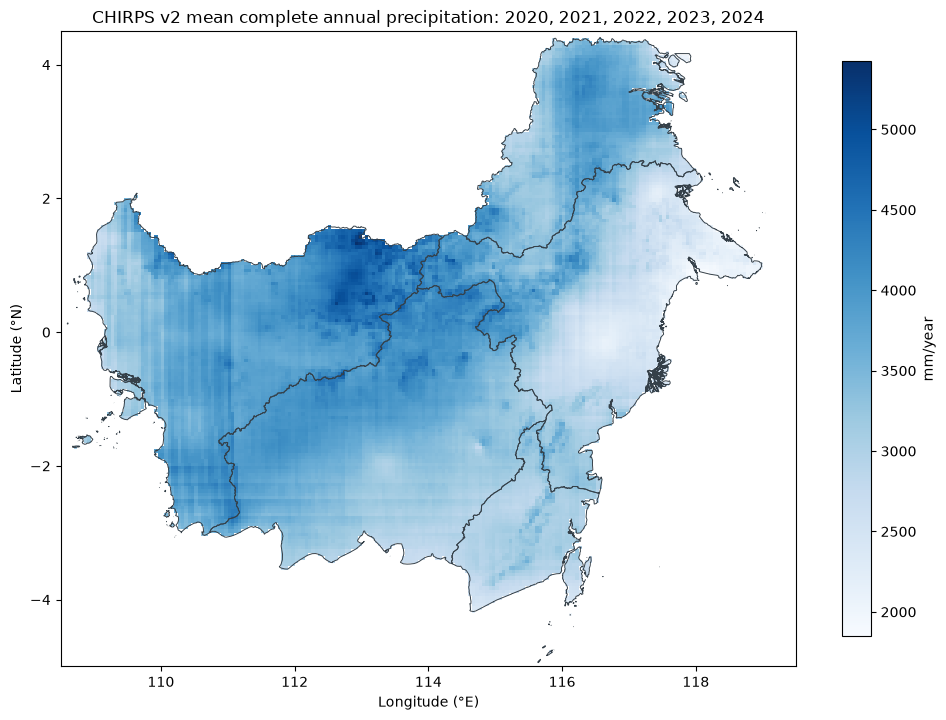

In [7]:
totals = summary["complete_annual_totals"]
if not totals:
    print("No complete calendar years: annual-total map withheld.")
else:
    complete_years = sorted(totals)
    mean_annual_total = np.mean(np.stack([totals[year] for year in complete_years]), axis=0)
    image = np.ma.masked_where(~province_mask | ~np.isfinite(mean_annual_total), mean_annual_total)
    transform = study.config["sources"]["chirps"]["grid_transform"]
    dx, _, west, _, dy, north = transform
    fig, ax = plt.subplots(figsize=(10, 8))
    im = ax.imshow(image, origin="upper", cmap="Blues", interpolation="nearest",
                   extent=[west, west+len(longitude)*dx, north+len(latitude)*dy, north])
    for _, geometry in provinces:
        plot_polygon(geometry.simplify(.003, preserve_topology=True), ax=ax,
                     add_points=False, facecolor="none", edgecolor="#354049", linewidth=.7)
    ax.set(xlabel="Longitude (°E)", ylabel="Latitude (°N)",
           title="CHIRPS v2 mean complete annual precipitation: " + ", ".join(map(str, complete_years)))
    ax.set_aspect("equal", adjustable="box")
    fig.colorbar(im, ax=ax, shrink=.75, label="mm/year")
    plt.tight_layout()
    plt.show()


## Interpretation before preprocessing

- Complete year totals and complete month climatology use actual calendar-day coverage; partial periods remain explicit.
- Missingness, source gaps and held-out access must remain visible in subsequent preparation.
- Rainfall measured on the target day is a retrospective covariate. These experiments do not establish predictor availability at a forecast issue cutoff.
- CHIRPS v3 is a separate migration experiment; this notebook never mixes product versions.
